# 05 — Avaliação única no teste (seções 17–22 e 25 do v5)

**Lê:** `selecao_modelo.json`, `painel` (treino + **teste via trava**), `panel_base` até `TRAIN_TARGET_END`, `coorte`, `perfis_treino`, `resumo_validacao`, `order_seller_revenue`.  
**Grava:** `previsoes_teste`, métricas, IC bootstrap, Diebold-Mariano, perfis, sensibilidade, tabela final.

Este é o **único** acesso confirmatório ao teste. A escolha não muda depois daqui.

In [1]:
# === SETUP (idêntico em todos os notebooks; só muda NOTEBOOK) ===
NOTEBOOK = "05_avaliacao_teste"
RAIZ = "/content/drive/MyDrive/tcc_fluxo"      # Colab. Localmente: caminho da pasta do projeto (ou deixe None)

import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q -r {RAIZ}/requirements.txt
except ImportError:                              # fora do Colab
    RAIZ = os.environ.get("TCC_RAIZ") or None
    if RAIZ is None:
        from pathlib import Path
        RAIZ = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").is_file()))
sys.path.insert(0, f"{RAIZ}/src")
%load_ext autoreload
%autoreload 2

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tcc_fluxo import iniciar
C, A = iniciar(RAIZ, notebook=NOTEBOOK)

AVISO de reprodutibilidade: pandas=3.1.1; referência recomendada=2.2.3
AVISO de reprodutibilidade: numpy=2.5.4; referência recomendada=2.1.3
AVISO de reprodutibilidade: scikit-learn=1.9.1; referência recomendada=1.6.1
Notebook: 05_avaliacao_teste | execução: v6_modular | raiz: C:\Users\andre\OneDrive\Documentos\Projetos\Tccv2\tcc_fluxo_modular_v6


In [2]:
from tcc_fluxo import avaliacao as AV, inferencia as INF, metricas as M, graficos, Especificacao

sel = A.carregar_json("selecao_modelo")
CHOSEN = sel["modelo_escolhido"]
spec_json = A.carregar_json("painel_spec")
spec = Especificacao.de_json(spec_json, C)
TEST_END = pd.Timestamp(A.carregar_json("corte")["TEST_END"])
train = A.carregar_treino()
test = A.carregar_teste(finalidade="confirmatoria")
hist = A.carregar_historico_treino()
resumo_val = A.carregar_df("resumo_validacao")

BOOST = sel["boost_models"]
RIDGE_NAME, RIDGE_ELIGIBLE = sel["ridge_alpha_documentado"], sel["ridge_elegivel"]
FINAL = ["Naive", "MediaMovel4", RIDGE_NAME, *BOOST]
ELIGIBLE = ["Naive", "MediaMovel4", *BOOST] + ([RIDGE_NAME] if RIDGE_ELIGIBLE else [])
print("Modelo escolhido na validação:", CHOSEN)

Modelo escolhido na validação: LightGBM_MAE_Exog


## 17. Reestimação com todo o treino e previsão do teste

In [3]:
test, comparison, pred_checks = AV.prever_teste(train, test, FINAL, ELIGIBLE, spec, spec.exog)
display(pred_checks)
A.salvar_df(comparison, "previsoes_teste")
A.tabela(comparison, "previsoes_teste.csv")

det = AV.auditoria_determinismo(train, test, BOOST, spec, C.DETERMINISM_TOL)
A.tabela(det, "auditoria_determinismo.csv"); display(det)
assert det.empty or det["deterministico"].all(), "previsões não reproduzíveis no mesmo ambiente"

Modelos ajustados no treino completo em 172s


,modelo,n_nao_finitas,n_negativas_brutas,pred_min,pred_max
0,Naive,0,0,0.0000,"11,830.5100"
1,MediaMovel4,0,0,0.0000,"8,947.2175"
2,Ridge_a10000,0,0,1.0523,"32,852,792.9888"
3,HistGB_MAE,0,0,0.0000,"3,054.3573"
4,HistGB_Poisson,0,0,17.6420,"6,632.5814"
5,LightGBM_MAE,0,1038,0.0000,"4,076.3430"
6,LightGBM_MAE_Exog,0,694,0.0000,"5,417.6370"
7,CatBoost_MAE,0,4037,0.0000,"5,147.5999"
8,CatBoost_MAE_raw,0,4223,0.0000,"4,087.2797"
9,CatBoost_Tweedie,0,0,4.6722,"5,208.9937"


,modelo,thread_count,seed,max_abs_diff,n_diferentes,tolerancia,deterministico
0,LightGBM_MAE,1,42,0.0000,0,0.0000,True
1,LightGBM_MAE_Exog,1,42,0.0000,0,0.0000,True
2,CatBoost_MAE,1,42,0.0000,0,0.0000,True
3,CatBoost_MAE_Exog,1,42,0.0000,0,0.0000,True
4,CatBoost_MAE_raw,1,42,0.0000,0,0.0000,True


In [4]:
scale_final = M.seller_scales(hist, C.TRAIN_TARGET_END)
agg_scale_final = M.aggregate_scale(hist, C.TRAIN_TARGET_END)
R = AV.metricas_teste(comparison, FINAL, ELIGIBLE, CHOSEN, scale_final, agg_scale_final)
A.tabela(R["vendedor_semana"], "metricas_teste_vendedor_semana.csv")
A.tabela(R["per_seller"], "metricas_por_vendedor.csv")
A.tabela(R["seller_summary"], "resumo_metricas_por_vendedor.csv")
A.tabela(R["agregado"], "metricas_teste_agregado.csv")
print("TESTE — nível vendedor-semana"); display(R["vendedor_semana"])
print("TESTE — total semanal da coorte"); display(R["agregado"])

TESTE — nível vendedor-semana


,modelo,elegivel_selecao,escolhido_validacao,MAE,RMSE,WAPE,sMAPE,MASE,skill_vs_naive,MASE_media,MASE_mediana,WAPE_media,skill_vs_naive_mediana,prop_vendedores_melhora
0,Naive,True,False,137.6889,385.4239,0.8619,57.1231,0.8287,0.0000,0.8287,0.6199,1.3827,0.0000,0.0000
1,MediaMovel4,True,False,127.3044,348.6360,0.7969,75.9832,0.7559,0.0754,0.7559,0.5839,1.3735,0.0747,0.6676
2,Ridge_a10000,False,False,"3,940.4904","264,846.4659",24.6667,185.4780,7.1960,-27.6188,7.1960,0.4748,2.6081,0.2323,0.7818
3,HistGB_MAE,True,False,157.3891,530.7494,0.9852,64.6163,0.7367,-0.1431,0.7367,0.4403,0.9989,0.2757,0.7717
4,HistGB_Poisson,True,False,134.0392,332.2528,0.8391,156.8176,0.9601,0.0265,0.9601,0.7635,2.1976,-0.0082,0.4899
5,LightGBM_MAE,True,False,110.1517,345.5540,0.6895,77.1228,0.6161,0.2000,0.6161,0.4508,0.9583,0.2723,0.9335
6,LightGBM_MAE_Exog,True,True,110.6348,344.1553,0.6926,75.9499,0.6165,0.1965,0.6165,0.4437,0.9425,0.2720,0.9436
7,CatBoost_MAE,True,False,110.1103,348.0190,0.6893,148.9985,0.6124,0.2003,0.6124,0.4419,0.9312,0.2819,0.9509
8,CatBoost_MAE_raw,True,False,112.9595,337.1471,0.7071,139.8229,0.6570,0.1796,0.6570,0.4839,1.2030,0.2133,0.8569
9,CatBoost_Tweedie,True,False,130.7832,351.0072,0.8187,158.4850,0.8994,0.0502,0.8994,0.6930,2.2709,0.0690,0.5795


TESTE — total semanal da coorte


,modelo,elegivel_selecao,escolhido_validacao,MAE,RMSE,WAPE,sMAPE,MASE,skill_vs_naive
0,Naive,True,False,"23,487.8243","29,616.7718",0.1690,18.6767,1.0019,0.0000
1,MediaMovel4,True,False,"24,670.0510","30,643.3185",0.1775,18.8736,1.0523,-0.0503
2,Ridge_a10000,False,False,"3,240,754.3908","9,059,682.7326",23.3178,104.8921,138.2320,-136.9759
3,HistGB_MAE,True,False,"136,287.1142","140,694.1232",0.9806,192.6701,5.8132,-4.8025
4,HistGB_Poisson,True,False,"20,952.5617","26,700.0605",0.1508,15.8001,0.8937,0.1079
5,LightGBM_MAE,True,False,"52,225.4308","57,665.1402",0.3758,45.1191,2.2276,-1.2235
6,LightGBM_MAE_Exog,True,True,"50,085.1390","56,075.3881",0.3604,42.9694,2.1363,-1.1324
7,CatBoost_MAE,True,False,"51,059.6693","57,463.7562",0.3674,44.1826,2.1779,-1.1739
8,CatBoost_MAE_raw,True,False,"40,348.1674","46,029.8923",0.2903,32.8743,1.7210,-0.7178
9,CatBoost_Tweedie,True,False,"28,790.4086","33,545.3866",0.2072,22.0942,1.2280,-0.2258


### Viés do total semanal (acréscimo da v6)
Uma perda MAE estima a **mediana** condicional. Em séries com muitas semanas zeradas, a mediana fica abaixo da média e a soma das previsões dos vendedores subestima o total. Esta tabela mostra o tamanho desse efeito no total da coorte.

In [5]:
vies = AV.vies_agregado(R["aggregate"], ELIGIBLE)
A.tabela(vies, "vies_total_semanal.csv"); display(vies)

,modelo,real_total,previsto_total,vies_pct_total,semanas_subestimadas,semanas
0,Naive,"4,725,392.6013","4,749,123.1948",0.5022,16,34
1,MediaMovel4,"4,725,392.6013","4,812,002.8894",1.8329,12,34
2,HistGB_MAE,"4,725,392.6013","91,630.7190",-98.0609,34,34
3,HistGB_Poisson,"4,725,392.6013","5,168,545.8445",9.3781,11,34
4,LightGBM_MAE,"4,725,392.6013","2,957,620.5692",-37.4101,33,34
5,LightGBM_MAE_Exog,"4,725,392.6013","3,045,107.7370",-35.5586,32,34
6,CatBoost_MAE,"4,725,392.6013","3,003,939.2745",-36.4298,33,34
7,CatBoost_MAE_raw,"4,725,392.6013","3,412,202.6229",-27.7901,32,34
8,CatBoost_Tweedie,"4,725,392.6013","4,025,224.4596",-14.8171,26,34
9,CatBoost_MAE_Exog,"4,725,392.6013","2,471,542.8944",-47.6966,33,34


## 18–19. Intervalos bootstrap e Diebold-Mariano (HLN)

In [6]:
ci = INF.intervalos_bootstrap(R["per_seller"], R["aggregate"], FINAL, C.N_BOOT, C.RANDOM_SEED)
A.tabela(ci, "intervalos_confianca.csv")
display(ci.loc[ci["metrica"].isin(["skill vs Naive (agrupado)", "MASE médio por vendedor",
                                   "proporção de vendedores com ganho", "skill vs Naive"])])

dm = INF.tabela_dm(comparison, R["aggregate"], FINAL, CHOSEN, C.N_BOOT, C.RANDOM_SEED, C.MIN_WEEKS_DM)
for nivel in dm["nivel"].unique():                 # acréscimo v6: Holm dentro de cada nível
    msk = dm["nivel"].eq(nivel)
    dm.loc[msk, "p_holm"] = INF.holm(dm.loc[msk, "p_valor_hln"].to_numpy(float))
A.tabela(dm, "teste_diebold_mariano.csv"); display(dm)

,modelo,metrica,estimativa,ic95_inf,ic95_sup,nivel,n_reamostragens
2,Naive,skill vs Naive (agrupado),0.0000,0.0000,0.0000,vendedor (bootstrap por vendedor),1000
3,Naive,MASE médio por vendedor,0.8287,0.7633,0.8937,vendedor (bootstrap por vendedor),1000
4,Naive,proporção de vendedores com ganho,0.0000,0.0000,0.0000,vendedor (bootstrap por vendedor),1000
7,MediaMovel4,skill vs Naive (agrupado),0.0754,0.0543,0.0953,vendedor (bootstrap por vendedor),1000
8,MediaMovel4,MASE médio por vendedor,0.7559,0.6982,0.8129,vendedor (bootstrap por vendedor),1000
9,MediaMovel4,proporção de vendedores com ganho,0.6676,0.6341,0.7010,vendedor (bootstrap por vendedor),1000
12,Ridge_a10000,skill vs Naive (agrupado),-27.6188,-70.5144,-2.3161,vendedor (bootstrap por vendedor),1000
13,Ridge_a10000,MASE médio por vendedor,7.1960,1.1830,18.8857,vendedor (bootstrap por vendedor),1000
14,Ridge_a10000,proporção de vendedores com ganho,0.7818,0.7496,0.8124,vendedor (bootstrap por vendedor),1000
17,HistGB_MAE,skill vs Naive (agrupado),-0.1431,-0.2330,-0.0523,vendedor (bootstrap por vendedor),1000


,nivel,modelo,referencia,n_semanas_efetivas,media_d (modelo - Naive),escolhido_validacao,aplicado,dm_hln,p_valor_hln,bloco,ic95_media_d_inf,ic95_media_d_sup,p_valor_bootstrap_blocos,observacao,p_holm
0,vendedor: perda absoluta média por semana,MediaMovel4,Naive,34,-10.3845,False,True,-5.0945,0.0000,4,-15.3099,-8.2266,0.0000,modelo erra menos que o Naive,0.0001
1,vendedor: perda absoluta média por semana,Ridge_a10000,Naive,34,"3,802.8015",False,True,2.2485,0.0313,4,696.8561,"8,526.8085",0.0420,modelo erra mais que o Naive,0.0453
2,vendedor: perda absoluta média por semana,HistGB_MAE,Naive,34,19.7002,False,True,4.7883,0.0000,4,10.1016,29.2658,0.0000,modelo erra mais que o Naive,0.0001
3,vendedor: perda absoluta média por semana,HistGB_Poisson,Naive,34,-3.6496,False,True,-2.3910,0.0227,4,-6.6447,-1.2610,0.0110,modelo erra menos que o Naive,0.0453
4,vendedor: perda absoluta média por semana,LightGBM_MAE,Naive,34,-27.5372,False,True,-15.2806,0.0000,4,-30.6069,-24.9070,0.0000,modelo erra menos que o Naive,0.0000
5,vendedor: perda absoluta média por semana,LightGBM_MAE_Exog,Naive,34,-27.0541,True,True,-15.4415,0.0000,4,-30.1067,-24.2360,0.0000,modelo erra menos que o Naive,0.0000
6,vendedor: perda absoluta média por semana,CatBoost_MAE,Naive,34,-27.5785,False,True,-15.7270,0.0000,4,-30.8084,-24.6708,0.0000,modelo erra menos que o Naive,0.0000
7,vendedor: perda absoluta média por semana,CatBoost_MAE_raw,Naive,34,-24.7293,False,True,-15.2276,0.0000,4,-27.4925,-22.0075,0.0000,modelo erra menos que o Naive,0.0000
8,vendedor: perda absoluta média por semana,CatBoost_Tweedie,Naive,34,-6.9056,False,True,-4.2117,0.0002,4,-9.5067,-3.5724,0.0000,modelo erra menos que o Naive,0.0006
9,vendedor: perda absoluta média por semana,CatBoost_MAE_Exog,Naive,34,-26.7202,False,True,-12.0101,0.0000,4,-30.5757,-22.7519,0.0000,modelo erra menos que o Naive,0.0000


## 20. Desempenho por perfil de vendedor

In [7]:
profile = A.carregar_df("perfis_treino").set_index("seller_id")
prof = AV.metricas_por_perfil(R["per_seller"], profile, CHOSEN, ELIGIBLE)
A.tabela(prof, "metricas_por_perfil.csv")
display(prof.loc[prof["modelo"].isin(ELIGIBLE)])

,perfil,modelo,n_vendedores,n_linhas,MAE,WAPE,MASE_medio,skill_vs_naive,mediana_ganho_vendedor,prop_vendedores_melhora,escolhido_validacao
0,intermitente,CatBoost_MAE,290,9860,38.8067,0.9891,0.5374,0.3823,0.4479,0.9803,False
1,intermitente,CatBoost_MAE_Exog,290,9860,38.8297,0.9897,0.5371,0.3819,0.4488,0.9803,False
2,intermitente,CatBoost_MAE_raw,290,9860,42.2181,1.0761,0.6058,0.3280,0.3310,0.9212,False
3,intermitente,CatBoost_Tweedie,290,9860,61.1830,1.5595,0.9947,0.0261,0.0132,0.5025,False
4,intermitente,HistGB_MAE,290,9860,39.2328,1.0000,0.5433,0.3755,0.4495,0.9803,False
5,intermitente,HistGB_Poisson,290,9860,67.6258,1.7237,1.1639,-0.0765,-0.2134,0.3251,False
6,intermitente,LightGBM_MAE,290,9860,39.1898,0.9989,0.5416,0.3762,0.4232,0.9803,False
7,intermitente,LightGBM_MAE_Exog,290,9860,38.7895,0.9887,0.5350,0.3826,0.4419,0.9951,True
8,intermitente,MediaMovel4,290,9860,59.4495,1.5153,0.7958,0.0537,0.0215,0.5665,False
9,intermitente,Naive,290,9860,62.8222,1.6013,0.8478,0.0000,0.0000,0.0000,False


## 21. Gráficos

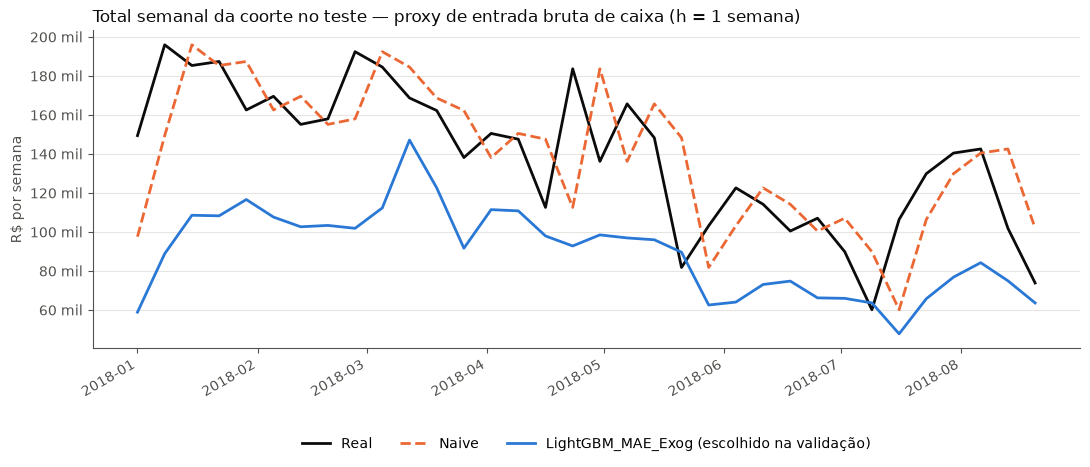

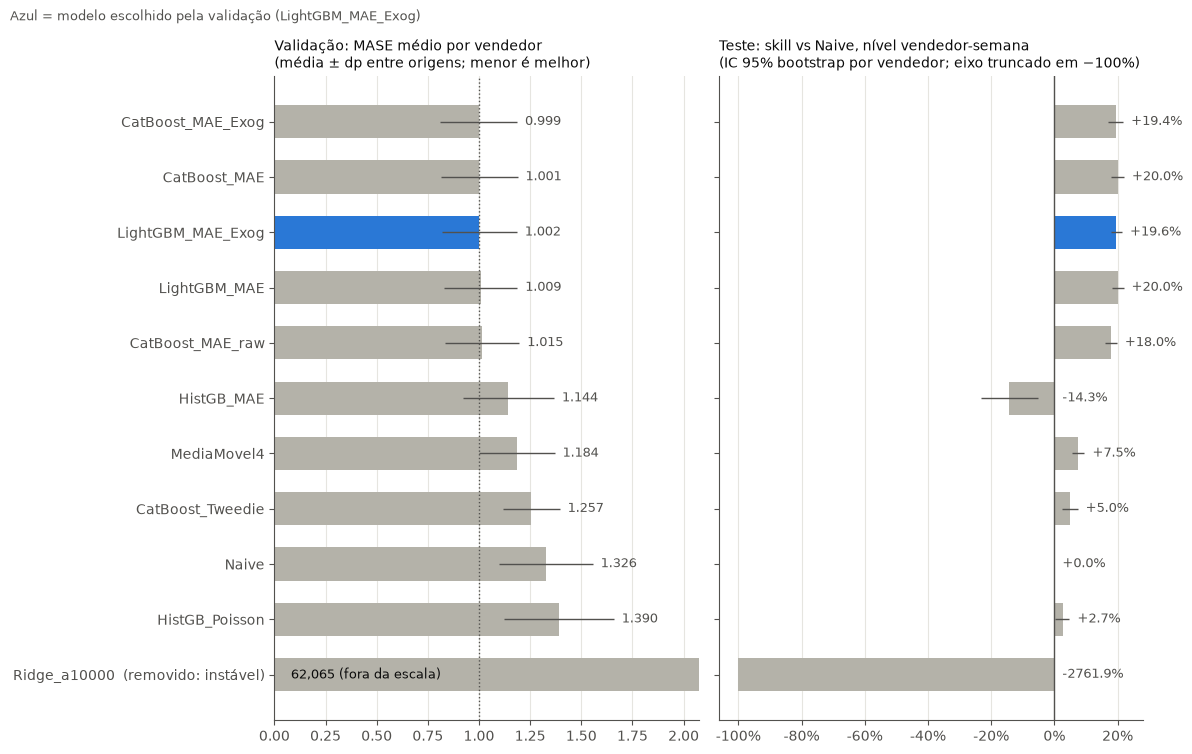

In [8]:
fig = graficos.agregado_teste(R["aggregate"], CHOSEN); A.figura(fig, "agregado_teste.png"); plt.show()
fig = graficos.comparacao_modelos(resumo_val, ci, FINAL, ELIGIBLE, CHOSEN, RIDGE_NAME, RIDGE_ELIGIBLE)
A.figura(fig, "comparacao_modelos.png"); plt.show()

## 22. Sensibilidade (não altera a escolha)

In [9]:
osr = A.carregar_df("order_seller_revenue")
cohort_idx = A.carregar_df("coorte")["seller_id"]
sens, share_nd, n_sem = AV.sensibilidade(comparison, ELIGIBLE, TEST_END, scale_final, agg_scale_final, osr, cohort_idx)
print(f"Teste SEM a semana-alvo {TEST_END.date()} ({n_sem} semanas):"); display(sens)
print(f"Participação de pedidos não 'delivered' no alvo do teste (coorte): {share_nd:.2%}")
A.tabela(sens, "sensibilidade_sem_ultima_semana.csv")

Teste SEM a semana-alvo 2018-08-20 (33 semanas):


,modelo,MAE,WAPE,skill_vs_naive,MASE_media,prop_vendedores_melhora,WAPE_agregado,skill_agregado
0,Naive,139.1759,0.8590,0.0000,0.8325,0.0000,0.1657,0.0000
1,MediaMovel4,127.9633,0.7898,0.0806,0.7587,0.6763,0.1685,-0.0174
2,HistGB_MAE,159.6960,0.9856,-0.1474,0.7462,0.7731,0.9810,-4.9219
3,HistGB_Poisson,135.2408,0.8347,0.0283,0.9660,0.4928,0.1436,0.1329
4,LightGBM_MAE,111.6340,0.6890,0.1979,0.6238,0.9350,0.3797,-1.2922
5,LightGBM_MAE_Exog,112.0875,0.6918,0.1946,0.6241,0.9408,0.3639,-1.1967
6,CatBoost_MAE,111.5624,0.6886,0.1984,0.6200,0.9494,0.3712,-1.2406
7,CatBoost_MAE_raw,114.4215,0.7062,0.1779,0.6652,0.8598,0.2945,-0.7776
8,CatBoost_Tweedie,132.2153,0.8160,0.0500,0.9076,0.5795,0.2063,-0.2454
9,CatBoost_MAE_Exog,112.5888,0.6949,0.1910,0.6221,0.9480,0.4798,-1.8963


Participação de pedidos não 'delivered' no alvo do teste (coorte): 1.92%


WindowsPath('C:/Users/andre/OneDrive/Documentos/Projetos/Tccv2/tcc_fluxo_modular_v6/execucoes/v6_modular/saidas/sensibilidade_sem_ultima_semana.csv')

## 25. Tabela final

In [10]:
final_table = AV.tabela_final(FINAL, ELIGIBLE, CHOSEN, resumo_val, ci, R["seller_summary"], R["agregado"])
A.tabela(final_table, "tabela_final_resultados.csv"); display(final_table)
A.salvar_json({"FINAL_MODELS": FINAL, "ELIGIBLE_FINAL": ELIGIBLE, "CHOSEN_MODEL": CHOSEN,
               "scale_final": scale_final.dropna().to_dict(), "agg_scale_final": agg_scale_final}, "avaliacao_teste")

,modelo,elegível,escolhido,VAL MASE médio vend.,TESTE MASE médio vend. [IC95],TESTE MASE mediano vend.,TESTE skill vend.-semana [IC95],TESTE % vend. que melhoram,TESTE WAPE agregado,TESTE skill agregado [IC95]
0,Naive,True,,1.3261,0.829 [0.763; 0.894],0.6199,+0.0% [+0.0%; +0.0%],0.0000,0.1690,+0.0% [+0.0%; +0.0%]
1,MediaMovel4,True,,1.1839,0.756 [0.698; 0.813],0.5839,+7.5% [+5.4%; +9.5%],0.6676,0.1775,-5.0% [-36.2%; +18.4%]
2,Ridge_a10000,False,,"62,065.0618",7.196 [1.183; 18.886],0.4748,-2761.9% [-7051.4%; -231.6%],0.7818,23.3178,-13697.6% [-25984.5%; -4543.3%]
3,HistGB_MAE,True,,1.1440,0.737 [0.673; 0.804],0.4403,-14.3% [-23.3%; -5.2%],0.7717,0.9806,-480.2% [-686.6%; -341.4%]
4,HistGB_Poisson,True,,1.3899,0.960 [0.905; 1.019],0.7635,+2.7% [+0.3%; +4.8%],0.4899,0.1508,+10.8% [-16.6%; +33.7%]
5,LightGBM_MAE,True,,1.0086,0.616 [0.567; 0.665],0.4508,+20.0% [+18.1%; +21.9%],0.9335,0.3758,-122.4% [-199.0%; -63.5%]
6,LightGBM_MAE_Exog,True,◀,1.0023,0.616 [0.568; 0.666],0.4437,+19.6% [+17.9%; +21.4%],0.9436,0.3604,-113.2% [-187.6%; -55.6%]
7,CatBoost_MAE,True,,1.0005,0.612 [0.564; 0.662],0.4419,+20.0% [+17.9%; +22.0%],0.9509,0.3674,-117.4% [-191.6%; -60.0%]
8,CatBoost_MAE_raw,True,,1.0146,0.657 [0.608; 0.708],0.4839,+18.0% [+16.2%; +19.8%],0.8569,0.2903,-71.8% [-128.5%; -28.2%]
9,CatBoost_Tweedie,True,,1.2565,0.899 [0.848; 0.954],0.6930,+5.0% [+2.4%; +7.4%],0.5795,0.2072,-22.6% [-61.0%; +6.8%]


{'arquivo': 'avaliacao_teste.json',
 'sha256': '50ec530e1c3f64ff21fd3dc68144180f97285cc119b9de053528ac70f5e0f6a0',
 'notebook': '05_avaliacao_teste',
 'criado_em': '2026-11-06T21:05:04',
 'entradas': {'selecao_modelo': 'e68d61585a18bb22b286f30394d241df1babe99f2db6b4a0dca6df17db450328',
  'painel_spec': 'b9cafb66abcafe0ebbd2c0f763ee324c6d077250a1ea02d79b7e3dbf4b65260f',
  'corte': 'c778cdb2b687163abee02bfdc83352d505599df8cd531f925b3254f7fc2d2271',
  'painel': '92db275746c6b1ba8cc4ba4949274317b8f7bcff71270ec54aa417a8ddfe3185',
  'panel_base': 'aa06ecccb0aed18a0deb82fbf20a698da9ccdde920f242ff71614aec8aadbf2a',
  'resumo_validacao': '909f168053c1452ab3b879c424dec59fc1517dc708be415aa9c74e0ecbea897c',
  'perfis_treino': '2c0886ca0a58e880a3d8071744060407b96e38f5e55d3def62ecbc11533f042e',
  'order_seller_revenue': 'dd1f31b90c34e4398a877682242f98e65b73dc5e9d6c786d61f9fbcb9ceafe9b',
  'coorte': 'a87c7af0c87a80f3c9872e4f6a2deab4ffcf633580b85fd136de67e8b04f9a48'}}

In [11]:
A.finalizar()

05_avaliacao_teste: leu 9 artefato(s), gravou 2.
